<a href="https://colab.research.google.com/github/Naux1118/HW3/blob/main/115066539_%E9%83%AD%E5%93%B2%E7%91%8B_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.optim as optims

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode

In [ ]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(path)
!ls {path}

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia
chest_xray


In [ ]:
device = torch.device('cuda')
gpu_count = torch.cuda.device_count()

print("Using", gpu_count, "GPUs")
print("CUDA is available:", torch.cuda.is_available())

Using 1 GPUs
CUDA is available: True


In [ ]:
# train loop
def train_one_epoch(model, device, criterion, optimizer, train_data_loader):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.train()

    for batch_idx, (images, labels) in enumerate (train_data_loader):
        images = images.to(device)
        labels = labels.to(device).float()
        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, labels.unsqueeze(1))

        # Calculating Loss
        epoch_loss.append(loss.item())

        # Calculating Metrics
        predicts = (preds > 0.5).float()
        predicts = predicts.view(-1)
        predicts = predicts.detach().cpu().numpy()
        labels = labels.detach().cpu().numpy()
        acc = accuracy_score(labels, predicts)

        epoch_acc.append(acc)

        # Backpropagation
        loss.backward()
        optimizer.step()

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    return epoch_loss, epoch_acc, total_time

# validation loop
def val_one_epoch(model, device, criterion, val_data_loader, best_acc, save):
    epoch_loss = []
    epoch_acc = []
    start_time = time.time()

    model.eval()

    with torch.no_grad():
        for images, labels in val_data_loader:
            images = images.to(device)
            labels = labels.to(device).float()
            preds = model(images)

            # Calculating Loss
            loss = criterion(preds, labels.unsqueeze(1))
            epoch_loss.append(loss.item())

            # Calculating Metrics
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            epoch_acc.append(acc)

    # Overall Epoch Results
    end_time = time.time()
    total_time = end_time - start_time

    epoch_loss = np.mean(epoch_loss)
    epoch_acc = np.mean(epoch_acc) * 100

    # Saving best model
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), f"{save}.pth")

    return epoch_loss, epoch_acc, total_time, best_acc

# evaluate loop (test loop)
def evaluate(model, device, model_path, test_loader):
    try:
        model.load_state_dict(torch.load(model_path))
        print("Model weights loaded successfully.")
    except Exception as e:
        print("Warning: Failed to load model weights. Using randomly initialized weights instead.")
        print(e)

    model.to(device)
    model.eval()

    test_loss = []
    test_acc = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).float()

            # Forward pass
            preds = model(images)

            # Calculating loss
            loss = criterion(preds, labels.unsqueeze(1))
            test_loss.append(loss.item())

            # Calculating accuracy
            predicts = (preds > 0.5).float()
            predicts = predicts.view(-1)
            predicts = predicts.detach().cpu().numpy()
            labels = labels.detach().cpu().numpy()
            acc = accuracy_score(labels, predicts)
            test_acc.append(acc)

    # Overall test results
    avg_test_loss = np.mean(test_loss)
    avg_test_acc = np.mean(test_acc) * 100

    print(f"Test Accuracy: {avg_test_acc:.2f}%")
    print(f"Test Loss: {avg_test_loss:.4f}")

    return avg_test_loss, avg_test_acc

In [ ]:
# define folder path for each set
train_path = f'{path}/chest_xray/train'
test_path = f'{path}/chest_xray/test'
val_path = f'{path}/chest_xray/val'

# define transformation
train_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

common_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

# create datasets
train_dataset = datasets.ImageFolder(train_path, transform=train_transform)
test_dataset = datasets.ImageFolder(test_path, transform=common_transform)
val_dataset = datasets.ImageFolder(val_path, transform=common_transform)

# create dataloaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [ ]:
for name, ds in [('train', train_dataset), ('val', val_dataset), ('test', test_dataset)]:
    n0 = ds.targets.count(0)   # NORMAL 張數
    n1 = ds.targets.count(1)   # PNEUMONIA 張數
    total = len(ds)
    print(f'{name:5s}  NORMAL={n0:4d}  PNEUMONIA={n1:4d}  total={total:4d}  PNEUMONIA佔比={n1/total*100:.2f}%')

print()
print('val 每答對/答錯一張，acc 變動:', 100 / len(val_dataset), '%')

train  NORMAL=1341  PNEUMONIA=3875  total=5216  PNEUMONIA佔比=74.29%
val    NORMAL=   8  PNEUMONIA=   8  total=  16  PNEUMONIA佔比=50.00%
test   NORMAL= 234  PNEUMONIA= 390  total= 624  PNEUMONIA佔比=62.50%

val 每答對/答錯一張，acc 變動: 6.25 %


In [ ]:
sizes = {'train': len(train_dataset), 'val': len(val_dataset), 'test': len(test_dataset)}
total_all = sum(sizes.values())

print(f'全部共 {total_all} 張')
for name, n in sizes.items():
    print(f'{name:5s} {n:5d} 張  佔 {n/total_all*100:.2f}%')

全部共 5856 張
train  5216 張  佔 89.07%
val      16 張  佔 0.27%
test    624 張  佔 10.66%


In [ ]:
# ===== 重新切分：train + 舊 val → 新 train / 新 val（類別比例同 test），test 不動 =====
from torch.utils.data import ConcatDataset, Subset

SPLIT_SEED = 42

# 同一批圖片讀兩份：一份套 train_transform 給新 train，一份套 common_transform 給新 val
pool_for_train = ConcatDataset([
    datasets.ImageFolder(train_path, transform=train_transform),
    datasets.ImageFolder(val_path,   transform=train_transform),
])
pool_for_val = ConcatDataset([
    datasets.ImageFolder(train_path, transform=common_transform),
    datasets.ImageFolder(val_path,   transform=common_transform),
])
pool_targets = np.array(pool_for_val.datasets[0].targets + pool_for_val.datasets[1].targets)

# 新 val 每類要抽的張數 = test 每類的張數
n_val_per_class = {c: test_dataset.targets.count(c) for c in (0, 1)}

rng = np.random.default_rng(SPLIT_SEED)
val_idx = []
for c, n in n_val_per_class.items():
    idx_c = np.where(pool_targets == c)[0]
    val_idx.extend(rng.choice(idx_c, size=n, replace=False).tolist())
val_set = set(val_idx)
train_idx = [i for i in range(len(pool_targets)) if i not in val_set]

train_dataset = Subset(pool_for_train, train_idx)
val_dataset   = Subset(pool_for_val, val_idx)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False)

# 檢查
for name, idx in [('新 train', train_idx), ('新 val', val_idx)]:
    t = pool_targets[idx]
    print(f'{name}: NORMAL={(t==0).sum()} PNEUMONIA={(t==1).sum()} 共{len(t)}')
print('重疊張數:', len(set(train_idx) & val_set))

新 train: NORMAL=1115 PNEUMONIA=3493 共4608
新 val: NORMAL=234 PNEUMONIA=390 共624
重疊張數: 0


In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(256 * 256 * 1, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 64),
    nn.BatchNorm1d(64),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(64, 1),
    nn.Sigmoid()
)

model.to(device)
print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=65536, out_features=64, bias=True)
  (2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (3): ReLU()
  (4): Dropout(p=0.5, inplace=False)
  (5): Linear(in_features=64, out_features=64, bias=True)
  (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): ReLU()
  (8): Dropout(p=0.5, inplace=False)
  (9): Linear(in_features=64, out_features=64, bias=True)
  (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=64, out_features=1, bias=True)
  (14): Sigmoid()
)


In [ ]:
# hyperparameter
lr = 0.001
weight_decay = 0.001
epochs = 10
optimizer = optims.Adam(model.parameters(), lr=lr, weight_decay = weight_decay)
lr_scheduler = optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
criterion = nn.BCELoss()

# save checkpoint
save = 'model'

In [ ]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_acc = 0.0
output_list = []

for epoch in range(epochs):
    train_loss, train_acc, train_time = train_one_epoch(model, device, criterion, optimizer, train_loader)
    val_loss, val_acc, val_time, best_acc = val_one_epoch(model, device, criterion, val_loader, best_acc, save)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    total_time = train_time + val_time
    output_str = f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - train_acc: {train_acc:.2f}% - val_loss: {val_loss:.4f} - val_acc: {val_acc:.2f}% - time: {total_time:.2f}s"
    output_list.append(output_str)
    print(output_str)
    lr_scheduler.step(val_acc)

Epoch 1/10 - loss: 0.4506 - train_acc: 80.69% - val_loss: 0.3733 - val_acc: 88.33% - time: 135.07s
Epoch 2/10 - loss: 0.2484 - train_acc: 91.64% - val_loss: 0.2808 - val_acc: 89.22% - time: 134.73s
Epoch 3/10 - loss: 0.1833 - train_acc: 93.36% - val_loss: 0.4551 - val_acc: 75.52% - time: 136.51s
Epoch 4/10 - loss: 0.1679 - train_acc: 94.27% - val_loss: 0.1765 - val_acc: 93.23% - time: 135.82s
Epoch 5/10 - loss: 0.1442 - train_acc: 95.05% - val_loss: 0.9437 - val_acc: 52.60% - time: 134.68s
Epoch 6/10 - loss: 0.1459 - train_acc: 95.01% - val_loss: 0.1875 - val_acc: 91.72% - time: 134.63s
Epoch 7/10 - loss: 0.1412 - train_acc: 94.92% - val_loss: 0.2442 - val_acc: 89.17% - time: 134.47s
Epoch 8/10 - loss: 0.1311 - train_acc: 95.72% - val_loss: 0.2329 - val_acc: 91.25% - time: 134.14s
Epoch 9/10 - loss: 0.1365 - train_acc: 94.94% - val_loss: 0.2437 - val_acc: 88.49% - time: 133.71s
Epoch 10/10 - loss: 0.1392 - train_acc: 94.90% - val_loss: 0.1484 - val_acc: 94.90% - time: 134.28s


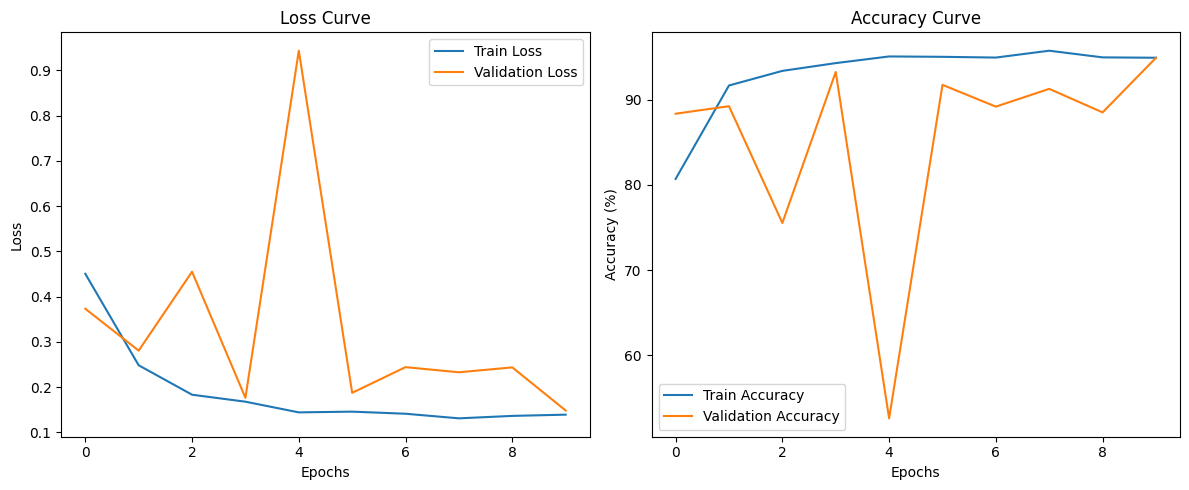

In [ ]:
plt.figure(figsize=(12, 5))

# loss graph
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# accuracy graph
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

# show
plt.tight_layout()
plt.show()

In [ ]:
model_path = 'model.pth'
avg_test_loss, avg_test_acc = evaluate(model, device, model_path, test_loader)

Model weights loaded successfully.
Test Accuracy: 82.60%
Test Loss: 0.4604


In [ ]:
# ===== 實驗工具：每組實驗都重建模型與 optimizer，結果記到 results =====
import pandas as pd
from torch.utils.data import ConcatDataset, Subset

NUM_WORKERS = 2            # 兩個 CPU 核心同時讀圖，只影響速度，不影響結果
criterion = nn.BCELoss()   # evaluate() 會用到這個全域變數
results = []               # 每組實驗一列，第 6 部分的總表用

test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_mlp(dropout=0.5):
    """baseline 的 MLP，與原本模型那格相同"""
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(256 * 256 * 1, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(64, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(64, 1), nn.Sigmoid(),
    )

def build_cnn(dropout=0.5):
    """小型 CNN：4 個 convolution block，參數約 6 萬個（MLP 約 420 萬個）"""
    def block(cin, cout):
        return [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(
        *block(1, 16), *block(16, 32), *block(32, 64), *block(64, 64),   # 256x256 → 16x16
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
        nn.Linear(64, 1), nn.Sigmoid(),
    )

def make_loaders(batch_size, train_tf):
    """新 train / 新 val 的 DataLoader（沿用重新切分那格的 train_idx、val_idx）"""
    train_pool = ConcatDataset([
        datasets.ImageFolder(train_path, transform=train_tf),
        datasets.ImageFolder(val_path,   transform=train_tf),
    ])
    tr = DataLoader(Subset(train_pool, train_idx), batch_size=batch_size, shuffle=True,  num_workers=NUM_WORKERS)
    va = DataLoader(Subset(pool_for_val, val_idx), batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    return tr, va

def make_optimizer(name, params, lr, weight_decay):
    if name == 'adam':         return optims.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == 'adamw':        return optims.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == 'sgd':          return optims.SGD(params, lr=lr, weight_decay=weight_decay)
    if name == 'sgd_momentum': return optims.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(f'不認得的 optimizer：{name}')

def make_scheduler(name, optimizer, epochs):
    if name == 'plateau': return optims.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, mode='max')
    if name == 'cosine':  return optims.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    if name == 'step':    return optims.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.1)
    if name == 'none':    return None
    raise ValueError(f'不認得的 scheduler：{name}')

def plot_history(name, h):
    ep = list(range(1, len(h['train_loss']) + 1))
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(ep, h['train_loss'], marker='o', label='Train Loss')
    plt.plot(ep, h['val_loss'], marker='o', label='Validation Loss')
    plt.title(f'Loss Curve ({name})'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.xticks(ep); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, h['train_acc'], marker='o', label='Train Accuracy')
    plt.plot(ep, h['val_acc'], marker='o', label='Validation Accuracy')
    plt.title(f'Accuracy Curve ({name})'); plt.xlabel('Epochs'); plt.ylabel('Accuracy (%)'); plt.xticks(ep); plt.legend()
    plt.tight_layout()
    plt.savefig(f'curves_{name}.png', dpi=150)
    plt.show()

def run_experiment(name, lr=0.001, weight_decay=0.001, optimizer='adam', batch_size=64,
                   epochs=10, scheduler='plateau', model_fn=build_mlp, train_tf=None, seed=42):
    """沒寫的參數都等於 baseline，所以每次只要寫出要改的那一個"""
    if train_tf is None:
        train_tf = train_transform
    print(f'===== {name} =====')
    set_seed(seed)
    tr_loader, va_loader = make_loaders(batch_size, train_tf)
    model = model_fn().to(device)                      # 每次都重建，不會接著上次的權重練
    opt = make_optimizer(optimizer, model.parameters(), lr, weight_decay)
    sched = make_scheduler(scheduler, opt, epochs)     # 一定在 optimizer 之後建立
    save = f'model_{name}'                             # 每組實驗各存一個檔，不會互相覆蓋

    h = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr']}
    best_acc, best_epoch, total_time = 0.0, 0, 0.0
    for epoch in range(epochs):
        cur_lr = opt.param_groups[0]['lr']
        tl, ta, tt = train_one_epoch(model, device, criterion, opt, tr_loader)
        vl, va, vt, new_best = val_one_epoch(model, device, criterion, va_loader, best_acc, save)
        if new_best > best_acc:
            best_epoch = epoch + 1
        best_acc = new_best
        total_time += tt + vt
        for k, v in zip(h, [tl, ta, vl, va, cur_lr]):
            h[k].append(v)
        print(f'Epoch {epoch+1}/{epochs} - lr: {cur_lr:.1e} - loss: {tl:.4f} - train_acc: {ta:.2f}% '
              f'- val_loss: {vl:.4f} - val_acc: {va:.2f}% - time: {tt+vt:.2f}s')
        if sched is not None:
            if scheduler == 'plateau':
                sched.step(va)
            else:
                sched.step()

    plot_history(name, h)
    test_loss, test_acc = evaluate(model, device, f'{save}.pth', test_loader)

    row = dict(name=name, model=model_fn.__name__, optimizer=optimizer, lr=lr, batch_size=batch_size,
               weight_decay=weight_decay, scheduler=scheduler, epochs=epochs,
               best_epoch=best_epoch, best_val_acc=round(best_acc, 2),
               test_acc=round(test_acc, 2), test_loss=round(test_loss, 4), time_min=round(total_time / 60, 1))
    results[:] = [r for r in results if r['name'] != name] + [row]
    pd.DataFrame(results).to_csv('results.csv', index=False)
    return h

print('實驗工具已載入')

實驗工具已載入


===== baseline =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.4506 - train_acc: 80.69% - val_loss: 0.3733 - val_acc: 88.33% - time: 119.31s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.2484 - train_acc: 91.64% - val_loss: 0.2808 - val_acc: 89.22% - time: 108.93s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.1833 - train_acc: 93.36% - val_loss: 0.4551 - val_acc: 75.52% - time: 105.19s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1679 - train_acc: 94.27% - val_loss: 0.1765 - val_acc: 93.23% - time: 104.73s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.1442 - train_acc: 95.05% - val_loss: 0.9437 - val_acc: 52.60% - time: 104.14s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.1459 - train_acc: 95.01% - val_loss: 0.1875 - val_acc: 91.72% - time: 108.42s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.1412 - train_acc: 94.92% - val_loss: 0.2442 - val_acc: 89.17% - time: 107.65s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1311 - train_acc: 95.72% - val_loss: 0.2329 - val_acc: 91.25% - time: 106.41s
Epoch 9/10 - lr: 1.0e-03 - loss: 0.1365 - train_acc: 94.94% - val_loss: 0.2

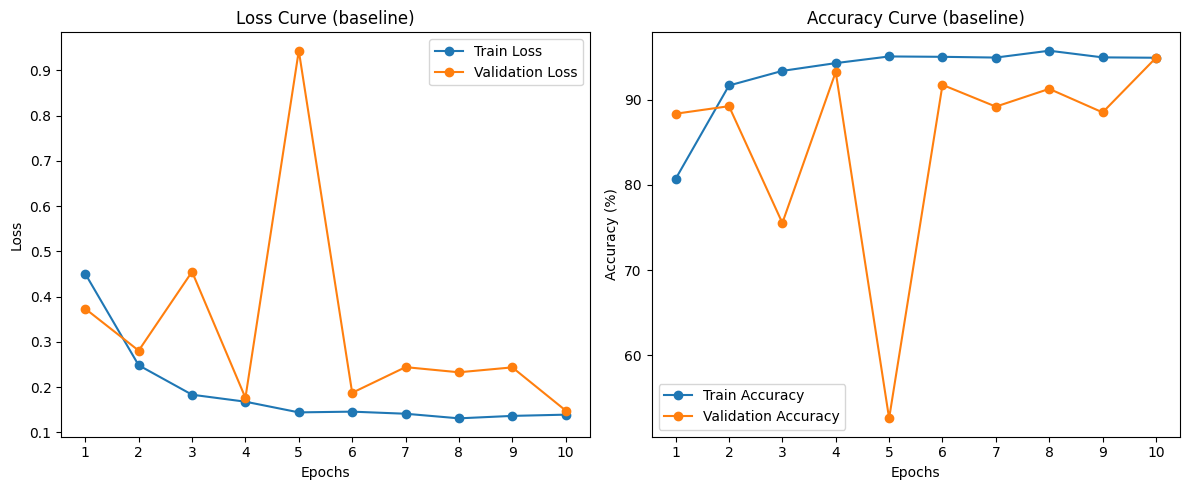

Model weights loaded successfully.
Test Accuracy: 82.60%
Test Loss: 0.4604


In [ ]:
# ===== 檢查：用新工具重跑 baseline，結果應接近之前的 test 82.60% =====
h_baseline = run_experiment('baseline')

===== lr_0.01 =====
Epoch 1/10 - lr: 1.0e-02 - loss: 0.3417 - train_acc: 85.37% - val_loss: 0.9524 - val_acc: 67.34% - time: 104.58s
Epoch 2/10 - lr: 1.0e-02 - loss: 0.2378 - train_acc: 90.84% - val_loss: 0.5660 - val_acc: 76.88% - time: 104.31s
Epoch 3/10 - lr: 1.0e-02 - loss: 0.2074 - train_acc: 92.53% - val_loss: 0.3203 - val_acc: 84.06% - time: 102.95s
Epoch 4/10 - lr: 1.0e-02 - loss: 0.2099 - train_acc: 92.36% - val_loss: 0.5476 - val_acc: 70.47% - time: 103.64s
Epoch 5/10 - lr: 1.0e-02 - loss: 0.2020 - train_acc: 92.25% - val_loss: 0.2734 - val_acc: 91.30% - time: 103.41s
Epoch 6/10 - lr: 1.0e-02 - loss: 0.2024 - train_acc: 92.34% - val_loss: 0.7077 - val_acc: 65.42% - time: 102.42s
Epoch 7/10 - lr: 1.0e-02 - loss: 0.2102 - train_acc: 92.30% - val_loss: 0.3205 - val_acc: 85.16% - time: 103.21s
Epoch 8/10 - lr: 1.0e-02 - loss: 0.2031 - train_acc: 92.30% - val_loss: 0.2631 - val_acc: 89.53% - time: 102.93s
Epoch 9/10 - lr: 1.0e-02 - loss: 0.2083 - train_acc: 92.01% - val_loss: 1.48

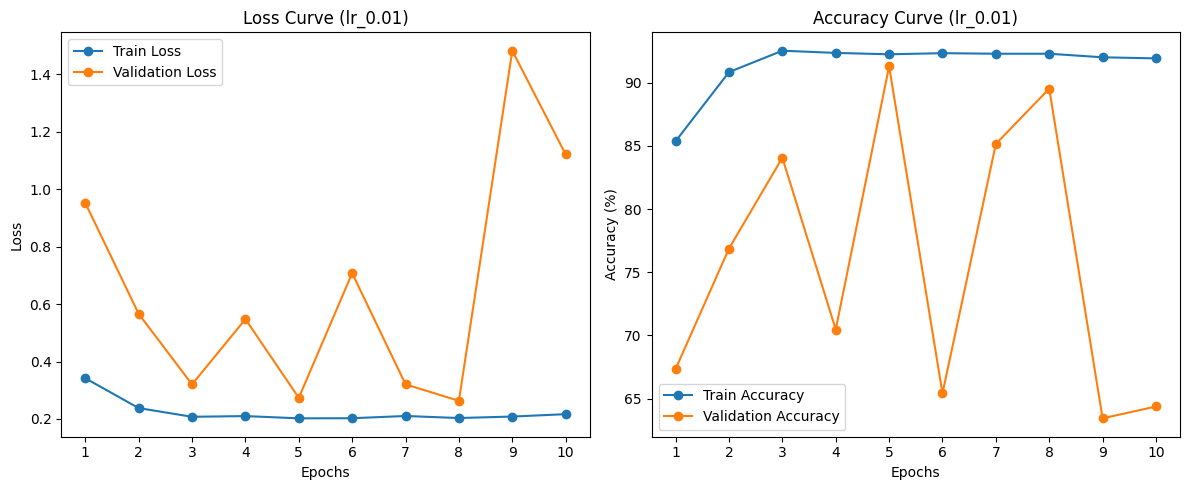

Model weights loaded successfully.
Test Accuracy: 79.58%
Test Loss: 0.4439
===== lr_0.0001 =====
Epoch 1/10 - lr: 1.0e-04 - loss: 0.5550 - train_acc: 75.04% - val_loss: 0.5376 - val_acc: 89.64% - time: 104.29s
Epoch 2/10 - lr: 1.0e-04 - loss: 0.4748 - train_acc: 83.53% - val_loss: 0.4851 - val_acc: 87.60% - time: 105.47s
Epoch 3/10 - lr: 1.0e-04 - loss: 0.4141 - train_acc: 87.54% - val_loss: 0.3599 - val_acc: 95.16% - time: 104.53s
Epoch 4/10 - lr: 1.0e-04 - loss: 0.3571 - train_acc: 90.91% - val_loss: 0.3255 - val_acc: 95.10% - time: 104.54s
Epoch 5/10 - lr: 1.0e-04 - loss: 0.3140 - train_acc: 93.10% - val_loss: 0.2960 - val_acc: 95.05% - time: 104.13s
Epoch 6/10 - lr: 1.0e-04 - loss: 0.2746 - train_acc: 94.01% - val_loss: 0.3121 - val_acc: 92.14% - time: 102.80s
Epoch 7/10 - lr: 1.0e-04 - loss: 0.2537 - train_acc: 94.36% - val_loss: 0.2917 - val_acc: 92.19% - time: 102.65s
Epoch 8/10 - lr: 1.0e-04 - loss: 0.2263 - train_acc: 95.20% - val_loss: 0.2452 - val_acc: 94.79% - time: 101.98s

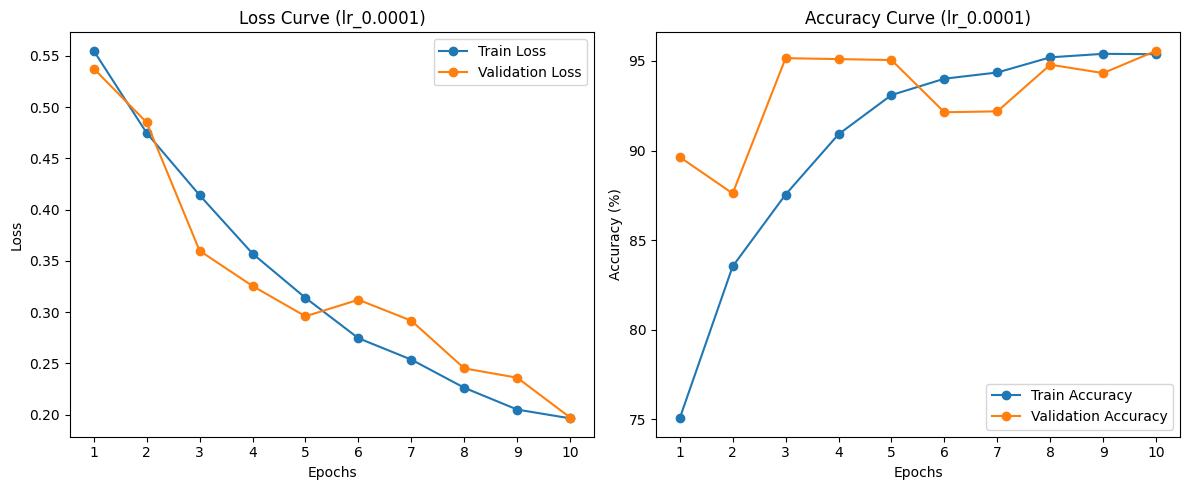

Model weights loaded successfully.
Test Accuracy: 77.14%
Test Loss: 0.5003
===== sgd_momentum =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.5285 - train_acc: 76.30% - val_loss: 0.5184 - val_acc: 77.03% - time: 103.04s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.4262 - train_acc: 79.21% - val_loss: 0.4547 - val_acc: 90.42% - time: 103.79s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.3637 - train_acc: 83.81% - val_loss: 0.3704 - val_acc: 92.97% - time: 104.36s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.3086 - train_acc: 87.87% - val_loss: 0.2898 - val_acc: 94.69% - time: 103.79s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.2662 - train_acc: 91.10% - val_loss: 0.2757 - val_acc: 94.69% - time: 104.11s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.2270 - train_acc: 92.43% - val_loss: 0.2312 - val_acc: 93.75% - time: 104.53s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.2085 - train_acc: 93.45% - val_loss: 0.1771 - val_acc: 95.05% - time: 103.84s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1845 - train_acc: 94.14% - val_loss: 0.1894 - val_acc: 94.64% - time: 103.

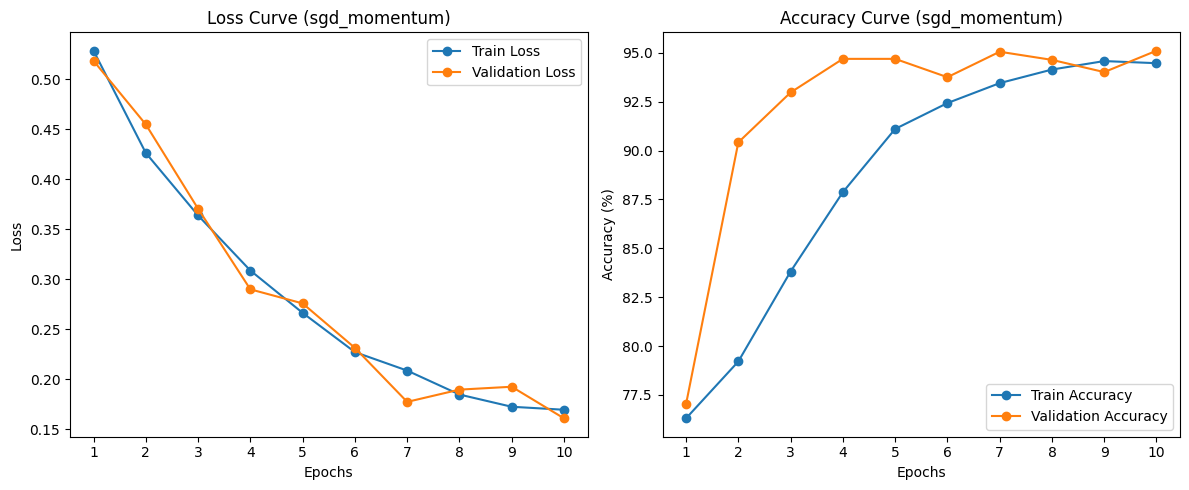

Model weights loaded successfully.
Test Accuracy: 80.05%
Test Loss: 0.4631


In [ ]:
# ===== 第 2 部分：優化設定（每組只改一個變數）=====
h_lr_high = run_experiment('lr_0.01',      lr=0.01)
h_lr_low  = run_experiment('lr_0.0001',    lr=0.0001)
h_sgd     = run_experiment('sgd_momentum', optimizer='sgd_momentum')

===== cosine =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.4506 - train_acc: 80.69% - val_loss: 0.3733 - val_acc: 88.33% - time: 104.99s
Epoch 2/10 - lr: 9.8e-04 - loss: 0.2491 - train_acc: 91.60% - val_loss: 0.3221 - val_acc: 85.47% - time: 106.83s
Epoch 3/10 - lr: 9.0e-04 - loss: 0.1846 - train_acc: 93.23% - val_loss: 0.3187 - val_acc: 84.48% - time: 107.75s
Epoch 4/10 - lr: 7.9e-04 - loss: 0.1652 - train_acc: 94.60% - val_loss: 0.3672 - val_acc: 83.75% - time: 106.12s
Epoch 5/10 - lr: 6.5e-04 - loss: 0.1470 - train_acc: 94.66% - val_loss: 0.3760 - val_acc: 79.48% - time: 104.50s
Epoch 6/10 - lr: 5.0e-04 - loss: 0.1318 - train_acc: 95.36% - val_loss: 0.1819 - val_acc: 92.66% - time: 104.93s
Epoch 7/10 - lr: 3.5e-04 - loss: 0.1192 - train_acc: 96.12% - val_loss: 0.2614 - val_acc: 87.19% - time: 105.71s
Epoch 8/10 - lr: 2.1e-04 - loss: 0.1066 - train_acc: 96.51% - val_loss: 0.1388 - val_acc: 94.32% - time: 106.80s
Epoch 9/10 - lr: 9.5e-05 - loss: 0.0989 - train_acc: 96.53% - val_loss: 0.112

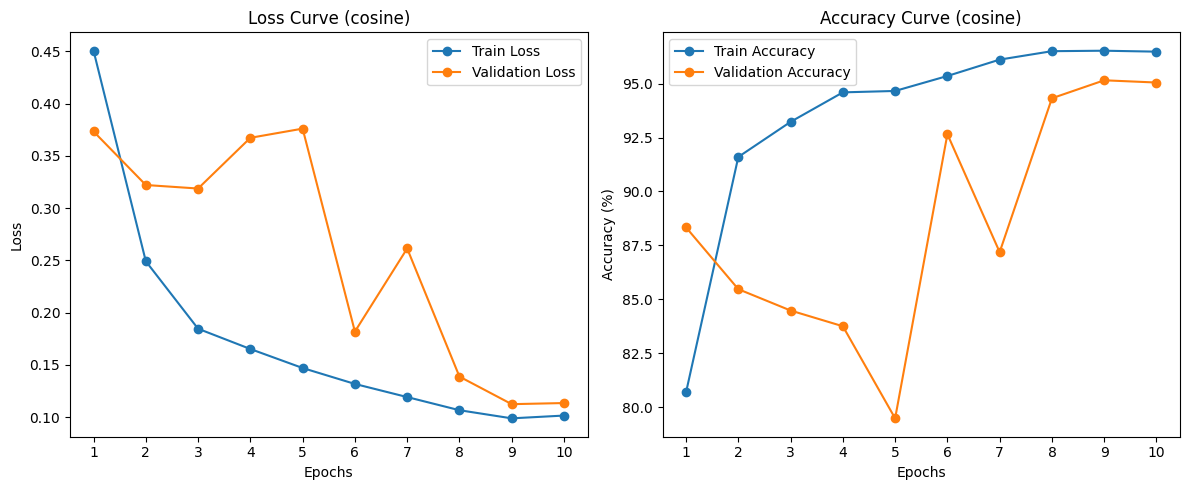

Model weights loaded successfully.
Test Accuracy: 79.79%
Test Loss: 0.6560
===== wd_0 =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.4508 - train_acc: 80.62% - val_loss: 0.3570 - val_acc: 89.90% - time: 105.58s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.2478 - train_acc: 91.73% - val_loss: 0.2611 - val_acc: 89.06% - time: 106.28s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.1790 - train_acc: 93.55% - val_loss: 0.2014 - val_acc: 91.30% - time: 105.53s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1591 - train_acc: 94.55% - val_loss: 0.1458 - val_acc: 94.53% - time: 104.72s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.1356 - train_acc: 95.20% - val_loss: 0.1290 - val_acc: 95.00% - time: 104.19s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.1169 - train_acc: 95.90% - val_loss: 0.2821 - val_acc: 89.84% - time: 104.54s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.1171 - train_acc: 95.96% - val_loss: 0.1791 - val_acc: 92.34% - time: 105.15s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1053 - train_acc: 96.25% - val_loss: 0.4683 - val_acc: 85.94% - time: 103.72s
Epoc

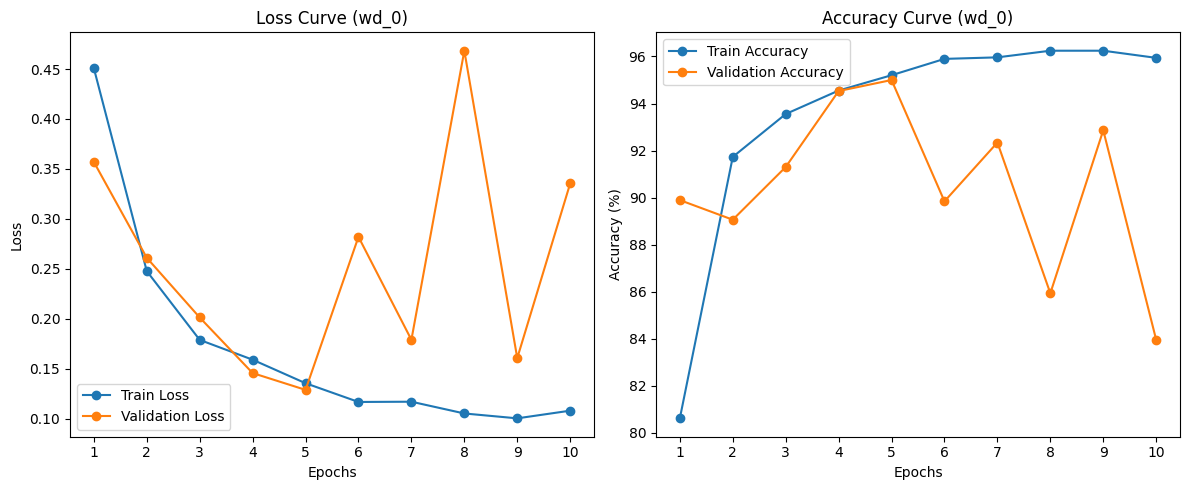

Model weights loaded successfully.
Test Accuracy: 75.89%
Test Loss: 0.7769
===== wd_0.01 =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.4552 - train_acc: 80.43% - val_loss: 0.3877 - val_acc: 82.97% - time: 104.44s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.2582 - train_acc: 91.86% - val_loss: 0.3030 - val_acc: 93.44% - time: 104.77s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.2095 - train_acc: 92.60% - val_loss: 0.2481 - val_acc: 92.34% - time: 104.73s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1984 - train_acc: 93.29% - val_loss: 0.3042 - val_acc: 90.99% - time: 104.48s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.1920 - train_acc: 92.93% - val_loss: 0.2490 - val_acc: 92.45% - time: 104.26s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.1781 - train_acc: 93.45% - val_loss: 0.2451 - val_acc: 92.03% - time: 104.67s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.1927 - train_acc: 92.88% - val_loss: 0.4472 - val_acc: 75.31% - time: 105.93s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1847 - train_acc: 93.16% - val_loss: 0.2307 - val_acc: 91.82% - time: 103.97s
E

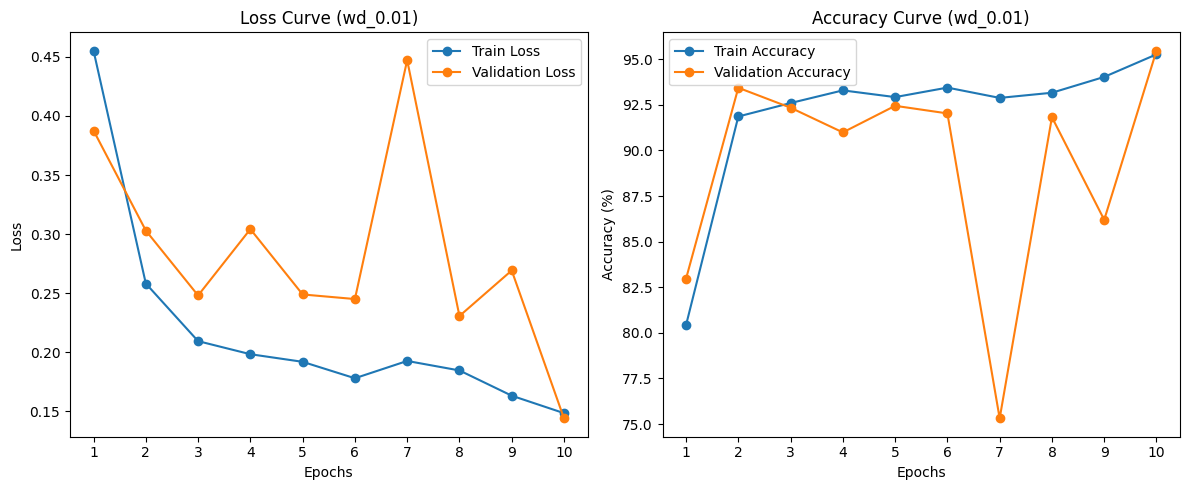

Model weights loaded successfully.
Test Accuracy: 80.36%
Test Loss: 0.4767


In [ ]:
# ===== 第 3 部分：訓練排程與正則化（每組只改一個變數）=====
h_cosine = run_experiment('cosine',   scheduler='cosine')
h_wd0    = run_experiment('wd_0',     weight_decay=0)
h_wd_hi  = run_experiment('wd_0.01',  weight_decay=0.01)

MLP 參數量: 4203137
CNN 參數量: 60641
===== cnn =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.3839 - train_acc: 84.14% - val_loss: 0.4770 - val_acc: 85.16% - time: 106.04s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.2456 - train_acc: 90.84% - val_loss: 0.3325 - val_acc: 85.05% - time: 105.26s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.2009 - train_acc: 92.66% - val_loss: 0.8821 - val_acc: 63.28% - time: 104.98s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1675 - train_acc: 94.08% - val_loss: 0.1817 - val_acc: 93.80% - time: 104.79s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.1625 - train_acc: 94.18% - val_loss: 0.5712 - val_acc: 71.72% - time: 105.26s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.1549 - train_acc: 94.53% - val_loss: 0.1869 - val_acc: 93.12% - time: 106.45s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.1308 - train_acc: 95.55% - val_loss: 0.3809 - val_acc: 83.75% - time: 105.02s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1360 - train_acc: 95.27% - val_loss: 0.2485 - val_acc: 89.38% - time: 104.84s
Epoch 9/10 - lr: 1.0e-03 - loss: 0.1230 - train_

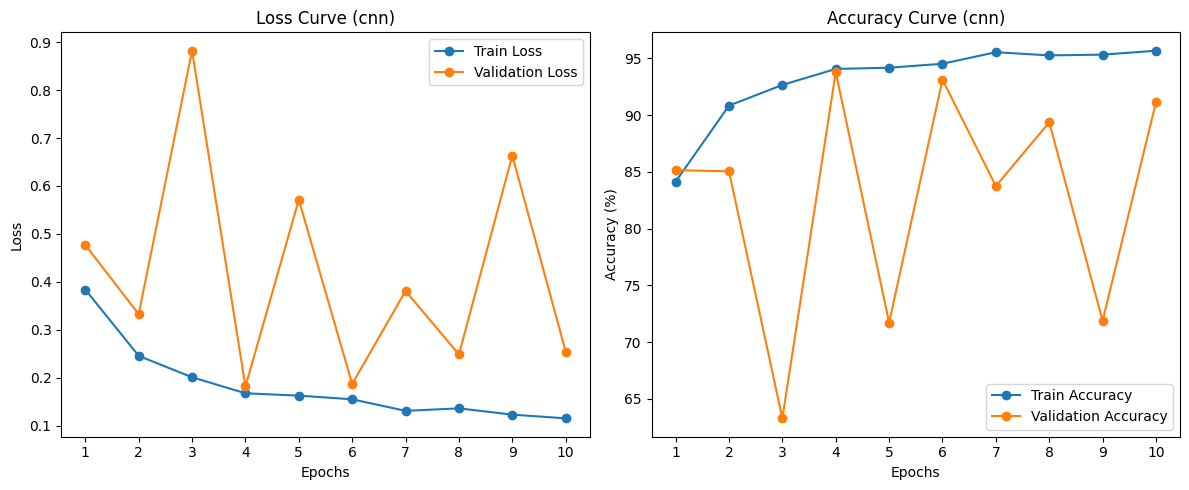

Model weights loaded successfully.
Test Accuracy: 78.59%
Test Loss: 0.5036


In [ ]:
# ===== 第 4 部分：模型架構（MLP → 小型 CNN）=====
print('MLP 參數量:', sum(p.numel() for p in build_mlp().parameters()))
print('CNN 參數量:', sum(p.numel() for p in build_cnn().parameters()))
h_cnn = run_experiment('cnn', model_fn=build_cnn)

===== aug_affine =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.5161 - train_acc: 75.91% - val_loss: 0.4363 - val_acc: 88.33% - time: 106.08s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.3496 - train_acc: 85.74% - val_loss: 0.2596 - val_acc: 91.25% - time: 105.43s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.2723 - train_acc: 89.47% - val_loss: 0.2157 - val_acc: 92.55% - time: 106.40s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.2511 - train_acc: 90.41% - val_loss: 0.2646 - val_acc: 90.31% - time: 105.56s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.2464 - train_acc: 89.97% - val_loss: 0.2200 - val_acc: 90.57% - time: 105.20s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.2304 - train_acc: 91.17% - val_loss: 0.1842 - val_acc: 93.33% - time: 105.39s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.2199 - train_acc: 91.08% - val_loss: 0.2642 - val_acc: 88.18% - time: 104.70s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.2268 - train_acc: 90.49% - val_loss: 0.1845 - val_acc: 93.33% - time: 105.32s
Epoch 9/10 - lr: 1.0e-03 - loss: 0.2252 - train_acc: 91.15% - val_loss: 0

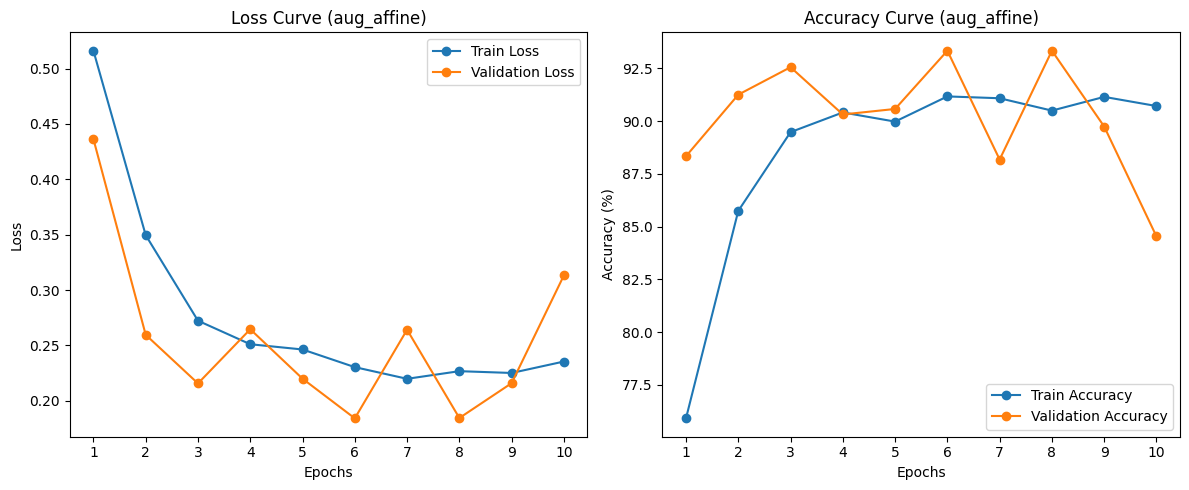

Model weights loaded successfully.
Test Accuracy: 76.93%
Test Loss: 0.5792
===== aug_hflip =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.4669 - train_acc: 79.58% - val_loss: 0.3648 - val_acc: 90.10% - time: 103.86s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.2556 - train_acc: 91.02% - val_loss: 0.3078 - val_acc: 88.44% - time: 103.38s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.1977 - train_acc: 92.77% - val_loss: 0.2194 - val_acc: 91.56% - time: 104.11s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1775 - train_acc: 93.40% - val_loss: 0.1732 - val_acc: 93.28% - time: 104.53s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.1638 - train_acc: 94.16% - val_loss: 0.2367 - val_acc: 89.01% - time: 104.41s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.1592 - train_acc: 94.27% - val_loss: 0.2232 - val_acc: 90.16% - time: 104.31s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.1557 - train_acc: 93.73% - val_loss: 0.2811 - val_acc: 86.04% - time: 104.27s
Epoch 8/10 - lr: 1.0e-03 - loss: 0.1563 - train_acc: 93.97% - val_loss: 0.1842 - val_acc: 93.12% - time: 104.80s

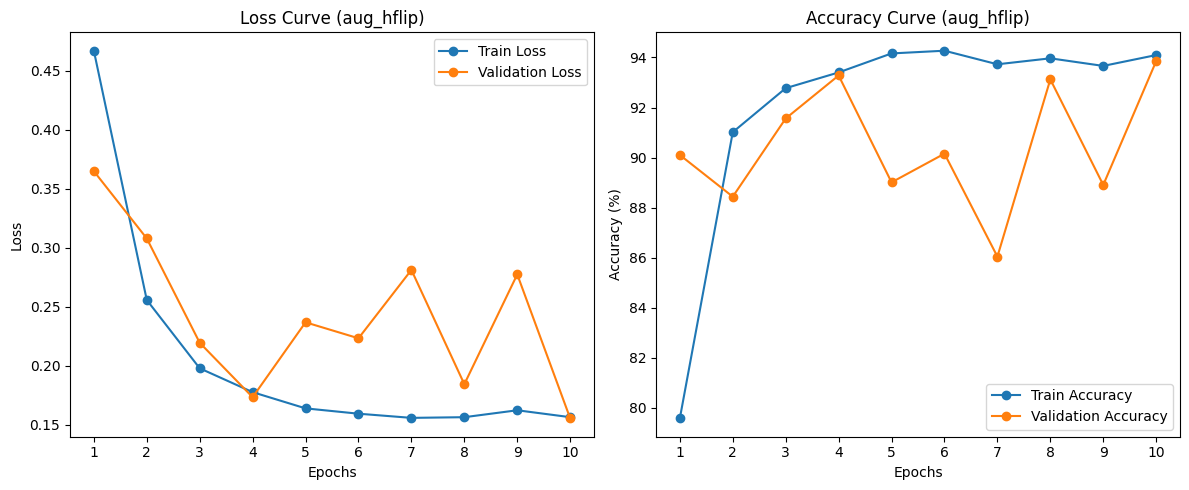

Model weights loaded successfully.
Test Accuracy: 78.96%
Test Loss: 0.5506


In [ ]:
# ===== 第 5 部分：資料增強（只加在新 train，val / test 不動）=====
aug_affine = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05)),   # 小角度旋轉 ±10° + 平移 5%
    transforms.ToTensor(),
])
aug_hflip = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(p=0.5),                         # 左右翻轉：心臟會跑到右邊
    transforms.ToTensor(),
])
h_aug_affine = run_experiment('aug_affine', train_tf=aug_affine)
h_aug_hflip  = run_experiment('aug_hflip',  train_tf=aug_hflip)

In [ ]:
# ===== 所有實驗的總表（也存成 results.csv）=====
pd.DataFrame(results)

,name,model,optimizer,lr,batch_size,weight_decay,scheduler,epochs,best_epoch,best_val_acc,test_acc,test_loss,time_min
0,baseline,build_mlp,adam,0.0010,64,0.001,plateau,10,10,94.90,82.60,0.4604,17.9
1,lr_0.01,build_mlp,adam,0.0100,64,0.001,plateau,10,5,91.30,79.58,0.4439,17.2
2,lr_0.0001,build_mlp,adam,0.0001,64,0.001,plateau,10,10,95.57,77.14,0.5003,17.3
3,sgd_momentum,build_mlp,sgd_momentum,0.0010,64,0.001,plateau,10,10,95.10,80.05,0.4631,17.3
4,cosine,build_mlp,adam,0.0010,64,0.001,cosine,10,9,95.16,79.79,0.6560,17.7
5,wd_0,build_mlp,adam,0.0010,64,0.000,plateau,10,5,95.00,75.89,0.7769,17.5
6,wd_0.01,build_mlp,adam,0.0010,64,0.010,plateau,10,10,95.47,80.36,0.4767,17.4
7,cnn,build_cnn,adam,0.0010,64,0.001,plateau,10,4,93.80,78.59,0.5036,17.6
8,aug_affine,build_mlp,adam,0.0010,64,0.001,plateau,10,6,93.33,76.93,0.5792,17.6
9,aug_hflip,build_mlp,adam,0.0010,64,0.001,plateau,10,10,93.85,78.96,0.5506,17.4


===== dropout_0.2 =====
Epoch 1/10 - lr: 1.0e-03 - loss: 0.2966 - train_acc: 90.86% - val_loss: 0.2204 - val_acc: 93.28% - time: 127.60s
Epoch 2/10 - lr: 1.0e-03 - loss: 0.1511 - train_acc: 94.84% - val_loss: 0.2025 - val_acc: 91.25% - time: 116.92s
Epoch 3/10 - lr: 1.0e-03 - loss: 0.1190 - train_acc: 96.01% - val_loss: 0.7845 - val_acc: 65.05% - time: 119.35s
Epoch 4/10 - lr: 1.0e-03 - loss: 0.1063 - train_acc: 96.16% - val_loss: 0.2187 - val_acc: 90.83% - time: 119.42s
Epoch 5/10 - lr: 1.0e-03 - loss: 0.0986 - train_acc: 96.72% - val_loss: 0.4044 - val_acc: 81.61% - time: 119.81s
Epoch 6/10 - lr: 1.0e-03 - loss: 0.0946 - train_acc: 96.79% - val_loss: 0.7137 - val_acc: 71.67% - time: 115.52s
Epoch 7/10 - lr: 1.0e-03 - loss: 0.0939 - train_acc: 96.44% - val_loss: 0.3739 - val_acc: 82.76% - time: 113.75s
Epoch 8/10 - lr: 1.0e-04 - loss: 0.0684 - train_acc: 97.63% - val_loss: 0.0902 - val_acc: 96.72% - time: 112.27s
Epoch 9/10 - lr: 1.0e-04 - loss: 0.0611 - train_acc: 98.03% - val_loss: 

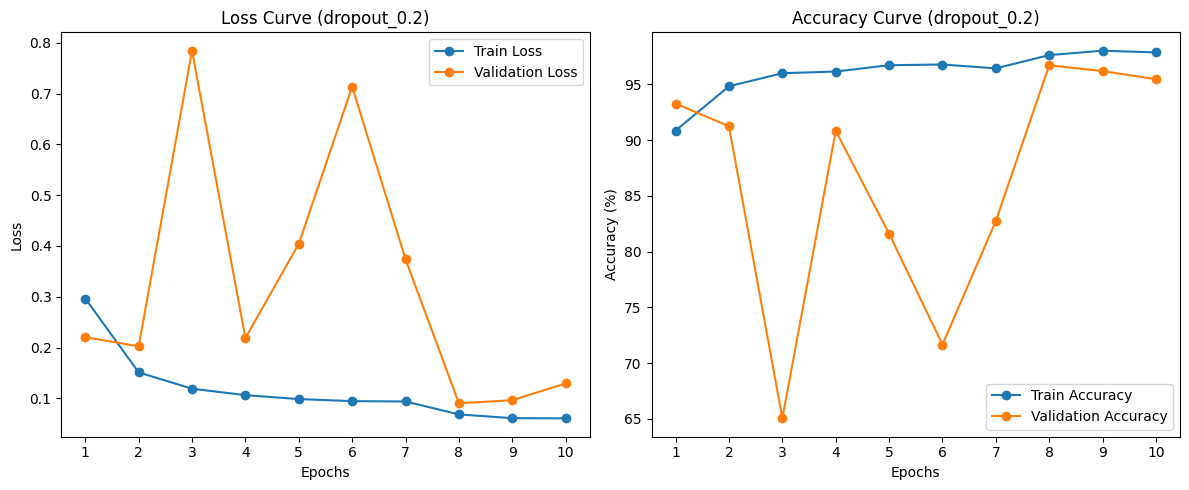

Model weights loaded successfully.
Test Accuracy: 78.54%
Test Loss: 0.7259
===== combo_lr1e-4_wd0.01 =====
Epoch 1/10 - lr: 1.0e-04 - loss: 0.5571 - train_acc: 74.93% - val_loss: 0.5600 - val_acc: 91.35% - time: 113.63s
Epoch 2/10 - lr: 1.0e-04 - loss: 0.4785 - train_acc: 82.79% - val_loss: 0.5083 - val_acc: 86.72% - time: 114.25s
Epoch 3/10 - lr: 1.0e-04 - loss: 0.4194 - train_acc: 87.54% - val_loss: 0.3791 - val_acc: 93.02% - time: 111.60s
Epoch 4/10 - lr: 1.0e-04 - loss: 0.3680 - train_acc: 90.80% - val_loss: 0.4314 - val_acc: 86.20% - time: 113.28s
Epoch 5/10 - lr: 1.0e-04 - loss: 0.3251 - train_acc: 92.23% - val_loss: 0.2667 - val_acc: 94.43% - time: 112.02s
Epoch 6/10 - lr: 1.0e-04 - loss: 0.2874 - train_acc: 93.95% - val_loss: 0.3494 - val_acc: 91.46% - time: 111.57s
Epoch 7/10 - lr: 1.0e-04 - loss: 0.2683 - train_acc: 94.18% - val_loss: 0.2659 - val_acc: 93.18% - time: 113.06s
Epoch 8/10 - lr: 1.0e-04 - loss: 0.2409 - train_acc: 95.10% - val_loss: 0.3139 - val_acc: 87.81% - tim

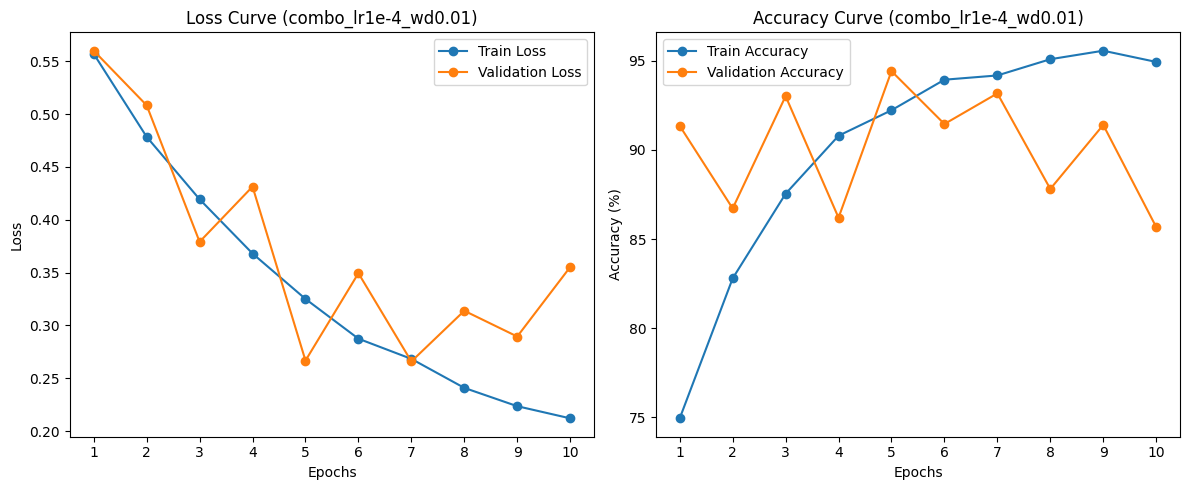

Model weights loaded successfully.
Test Accuracy: 78.54%
Test Loss: 0.4464


,name,model,optimizer,lr,batch_size,weight_decay,scheduler,epochs,best_epoch,best_val_acc,test_acc,test_loss,time_min
0,dropout_0.2,build_mlp_dropout02,adam,0.0010,64,0.001,plateau,10,8,96.72,78.54,0.7259,19.5
1,combo_lr1e-4_wd0.01,build_mlp,adam,0.0001,64,0.010,plateau,10,5,94.43,78.54,0.4464,18.7


In [ ]:
# ===== 補充實驗：第 4 部分 dropout 0.2、第 6 部分組合實驗 =====
# 組合實驗的挑法：第 2、第 3 部分各取 val acc 最高的設定（lr 0.0001、weight decay 0.01），完全不看 test
def build_mlp_dropout02():
    return build_mlp(dropout=0.2)

h_dropout02 = run_experiment('dropout_0.2', model_fn=build_mlp_dropout02)
h_combo     = run_experiment('combo_lr1e-4_wd0.01', lr=0.0001, weight_decay=0.01)
pd.DataFrame(results)